# PerfuSense AI · Lesson 1: build a Transformer from scratch

**Goal of this notebook:** read 30 seconds of pressure-mat frames and say whether the person is lying **supine** (on the back), on the **left** side, or on the **right** side. On the way we build every piece of a Transformer by hand, so you understand it, not just call it.

You already know TensorFlow/Keras, scikit-learn and some data wrangling. This lesson adds:

1. Looking at a real dataset before trusting it.
2. Turning a big hospital mat into our small 10×10 mat.
3. Why we split data **by person** (and what goes wrong if we don't).
4. A baseline first, then the Transformer: tokens, embeddings, positions, attention, multi-head attention, encoder blocks.
5. Honest evaluation on people the model has never seen.

**How to use it:** run the cells from top to bottom (Shift+Enter). Read the text before each code cell. Cells marked **Your turn** are small experiments for you.

> PerfuSense is a research prototype, not a medical device. Nothing here is a clinical claim.

## Part 0 · Decisions before any code

### Decision 1: which framework?

**TensorFlow / Keras.** You already know it, and the project plan (PRD Appendix D) is written in it. PyTorch would work as well; the ideas in this notebook are the same in both.

### Decision 2: which data do we start with?

I opened all five downloads. Only two of them contain data. The other three are code repositories with download scripts:

| Download | What is inside | Can we train on it today? |
|---|---|---|
| `pmd-1.0.0.zip` (PmatData) | **Real data.** Exp. I: 13 people × 17 positions, 32×64 mat, 1 frame per second, 62–211 frames per recording. Exp. II: 8 people, 29 states, one averaged frame each, air and sponge mattress | **Yes** |
| `PoPu-main.zip` | **Real data.** 60 people × 28 positions + empty bed. Top sheet 27×64 and under-mattress sheet 12×6. 10 snapshots per recording, 3 small shifts per position | **Yes** |
| `SLP-Dataset-and-Code-master.zip` | Code only. The data needs a request form with an institution email | Not yet |
| `bodies-at-rest-master.zip` (PressurePose) | Code + download scripts. Synthetic set is ~10 GB, real set ~10 GB, needs a free SMPL account | Not yet |
| `BodyPressure-master.zip` (BodyPressureSD) | Code + download scripts. Synthetic set is 8.5 GB | Not yet |

**We start with PmatData Experiment I**, because it is the only one with real *time sequences* (about 1–3 minutes per recording). A Transformer over time needs time. PoPu comes in Lesson 2 (it gives us the "empty bed" class).

### Decision 3: what exactly does the model see and say?

| | Shape | Meaning |
|---|---|---|
| Input | `(30, 10, 10)` | 30 frames, one per second, each 10×10 cells |
| Output | `(3,)` | one score per class: supine, left, right |

"Empty bed" is not a class yet; PmatData has no empty recordings.

## The differences that confuse everyone

Words we will use all the time. Many of them sound alike but mean different things.

**Data words**

| Word | In this project | Example |
|---|---|---|
| **frame** | one reading of the whole mat at one moment | a 10×10 grid, 1 per second |
| **recording** | one file: one person in one position for 1–3 min | `S3/2.txt` = person 3, position 2 |
| **window** | a slice of 30 consecutive frames from one recording | frames 10–39 |
| **sample** | one training example = one window + its label | (window, "left") |
| **token** | one element of the sequence the Transformer reads | here one token = one frame |

**Training words**

| Word | Meaning |
|---|---|
| **batch** | a group of samples processed together (we use 32) |
| **step** | one weight update = one batch |
| **epoch** | one pass over all training samples = many steps |
| **parameter** | a number the model learns (a weight) |
| **hyperparameter** | a number *we* choose (learning rate, number of heads, window length) |
| **logits** | raw scores out of the last layer, any real number |
| **probabilities** | logits after softmax: between 0 and 1, sum to 1 |

**Split words**

| Set | Used for | Rule |
|---|---|---|
| **train** | learning the weights | the model sees it many times |
| **validation** | choosing hyperparameters, early stopping | the model never trains on it |
| **test** | the final honest number | look at it once, at the end |

**State vs event** (important for PerfuSense)

- A **state** lasts: "the patient is lying on the left side" (minutes to hours).
- An **event** is a moment of change: "the patient was turned from left to supine at 14:02".

The model in this notebook classifies **states**. Events come later, by comparing consecutive predictions over time ("it was left for 10 windows, now it is supine for 10 windows → a turn happened"). That event logic belongs on the server, next to the turn timers. Keeping the two apart makes each one simple to test.

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

keras.utils.set_random_seed(42)  # same random numbers every run, so results are repeatable
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


### Where the data lives

The datasets are **not** in the git repo (too big, and each has its own licence). By default the notebook looks in `D:\Projects\Perfusense\datasets`, i.e. three folders up from this notebook. On another computer, set the environment variable `PERFUSENSE_DATA` to your datasets folder.

In [2]:
DATA_ROOT = Path(os.environ.get("PERFUSENSE_DATA", "../../../datasets")).resolve()
PMD = DATA_ROOT / "pmd-1.0.0" / "a-pressure-map-dataset-for-in-bed-posture-classification-1.0.0"
EXP1 = PMD / "experiment-i"

assert EXP1.exists(), f"PmatData not found at {EXP1}. Unzip pmd-1.0.0.zip there or set PERFUSENSE_DATA."
print(sorted(p.name for p in EXP1.iterdir()))

['S1', 'S10', 'S11', 'S12', 'S13', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'subject-info-i.csv']


## Part 1 · Look at the raw data first

Each Experiment I file is plain text: **one row per frame**, 2048 numbers per row (= 32 × 64 sensors). The dataset page says the values are 0–1000 and each file is "about 120 frames". Let's check instead of trusting it.

In [3]:
def load_pmd_exp1(path):
    """One PmatData Exp. I file -> array (frames, 64, 32). Rows = head-to-foot, columns = left-to-right."""
    table = pd.read_csv(path, sep=r"\s+", header=None).to_numpy(dtype="float32")
    assert table.shape[1] == 2048, table.shape
    return table.reshape(-1, 64, 32)

rec = load_pmd_exp1(EXP1 / "S1" / "1.txt")
print("shape:", rec.shape, "| min:", rec.min(), "| max:", rec.max())

shape: (82, 64, 32) | min: 0.0 | max: 3841.0


Two surprises already:

- The maximum is **above 1000** in several files (up to 4095 across the dataset, which is the top of a 12-bit sensor). The documentation is not exact.
- Files have **62 to 211 frames**, not always 120.

Lesson: **trust, but verify.** We will scale every window by its own values later, so the exact range does not matter, but we would never have known without looking.

The reshape `(64, 32)` is a choice too: is each row of 2048 numbers stored as 64 rows of 32, or 32 rows of 64? The only way to know is to draw it. A person should appear, head at one end.

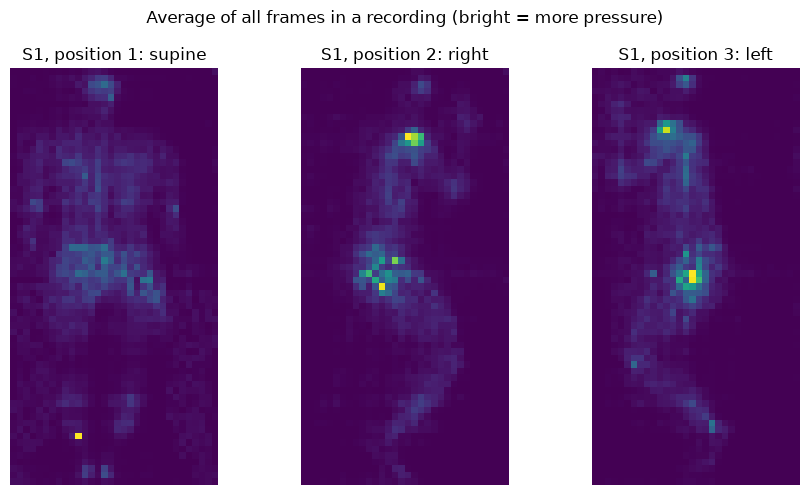

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(9, 5))
for ax, (pos, name) in zip(axes, [(1, "supine"), (2, "right"), (3, "left")]):
    frames = load_pmd_exp1(EXP1 / "S1" / f"{pos}.txt")
    ax.imshow(frames.mean(axis=0), cmap="viridis")
    ax.set_title(f"S1, position {pos}: {name}")
    ax.axis("off")
plt.suptitle("Average of all frames in a recording (bright = more pressure)")
plt.tight_layout()
plt.show()

A body shape appears, with the head at the top and the heels at the bottom, so `(64, 32)` is right. On the side positions the pressure is narrower and shifted, as you would expect.

### Labels

The 17 position numbers are explained in `experiment-info.docx` (as a picture of a table, so I typed it here). We only need three classes, so we map each position:

| Positions | Description | Our class |
|---|---|---|
| 1, 8, 9, 10, 11, 12 | supine, flat bed | supine |
| 15, 16, 17 | supine, head of bed raised 30°, 45°, 60° | supine |
| 2, 4, 5 | right side: flat, 30° wedge, 60° wedge | right |
| 13 | right foetal | right |
| 3, 6, 7 | left side: flat, 30° wedge, 60° wedge | left |
| 14 | left foetal | left |

Note: 9 positions are supine but only 4 are left and 4 are right. **The classes are unbalanced.** We will deal with that.

In [5]:
CLASSES = ["supine", "left", "right"]
POSITION_TO_CLASS = {
    1: "supine", 8: "supine", 9: "supine", 10: "supine", 11: "supine", 12: "supine",
    15: "supine", 16: "supine", 17: "supine",
    2: "right", 4: "right", 5: "right", 13: "right",
    3: "left", 6: "left", 7: "left", 14: "left",
}

recordings = []  # one dict per file
t0 = time.time()
subject_dirs = [p for p in EXP1.glob("S*") if p.is_dir()]  # skips subject-info-i.csv
for subject_dir in sorted(subject_dirs, key=lambda p: int(p.name[1:])):
    subject = int(subject_dir.name[1:])
    for pos, label in POSITION_TO_CLASS.items():
        frames = load_pmd_exp1(subject_dir / f"{pos}.txt")
        recordings.append({"subject": subject, "position": pos, "label": label, "frames": frames})
print(f"loaded {len(recordings)} recordings in {time.time() - t0:.0f} s")

summary = pd.DataFrame([{k: r[k] for k in ("subject", "position", "label")} | {"n_frames": len(r["frames"])}
                        for r in recordings])
print(summary.groupby("label").agg(recordings=("position", "size"), frames=("n_frames", "sum")))

loaded 221 recordings in 14 s
        recordings  frames
label                     
left            52    4739
right           52    4672
supine         117   10613


### Is anything moving?

A Transformer over time is useful when *what happens over time* matters. Let's measure how much each frame differs from the previous one in a recording, and the total pressure on the mat over time.

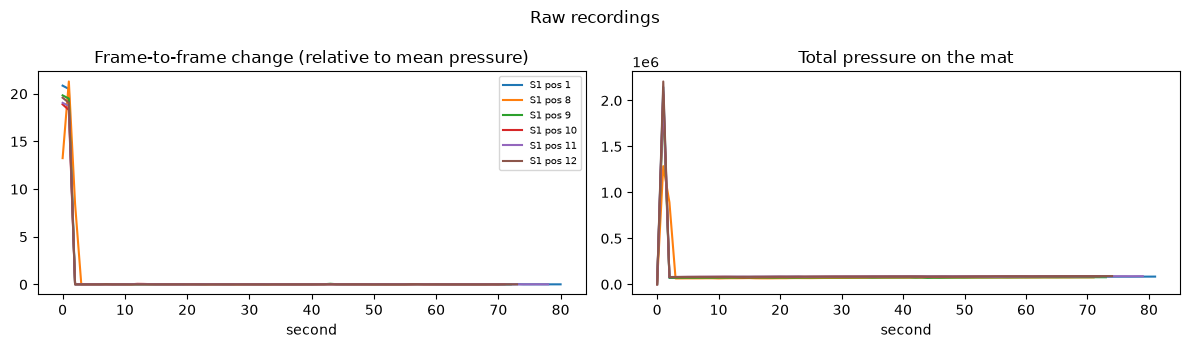

In [6]:
def plot_over_time(recs, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for r in recs:
        f = r["frames"]
        change = np.abs(np.diff(f, axis=0)).mean(axis=(1, 2)) / f.mean()
        axes[0].plot(change, label=f"S{r['subject']} pos {r['position']}")
        axes[1].plot(f.sum(axis=(1, 2)))
    axes[0].set_title("Frame-to-frame change (relative to mean pressure)")
    axes[1].set_title("Total pressure on the mat")
    for ax in axes: ax.set_xlabel("second")
    axes[0].legend(fontsize=7)
    plt.suptitle(title); plt.tight_layout(); plt.show()

plot_over_time(recordings[:6], "Raw recordings")

### We found a problem: startup frames

Look at the first seconds. The total pressure jumps to about **25 times** its normal value and then drops. When I checked all 221 files, frames 0 and 1 are abnormal in **every** file (a few files have a third or more). They are the mat starting up, not a person.

If we keep them, the first window of every recording contains a giant spike, and per-window scaling (Part 2) would squash the real body to almost zero. This is the most common way real data breaks a model, and it only shows up if you **plot before you train**.

**Cleaning rule:** inside each recording, drop any frame whose total pressure is more than 3× or less than ⅓ of the recording's median. A rule based on the data catches all cases, including the rare files where a bad frame appears later.

removed 461 frames in total; per file: {np.int64(2): np.int64(215), np.int64(3): np.int64(4), np.int64(4): np.int64(1), np.int64(15): np.int64(1)}


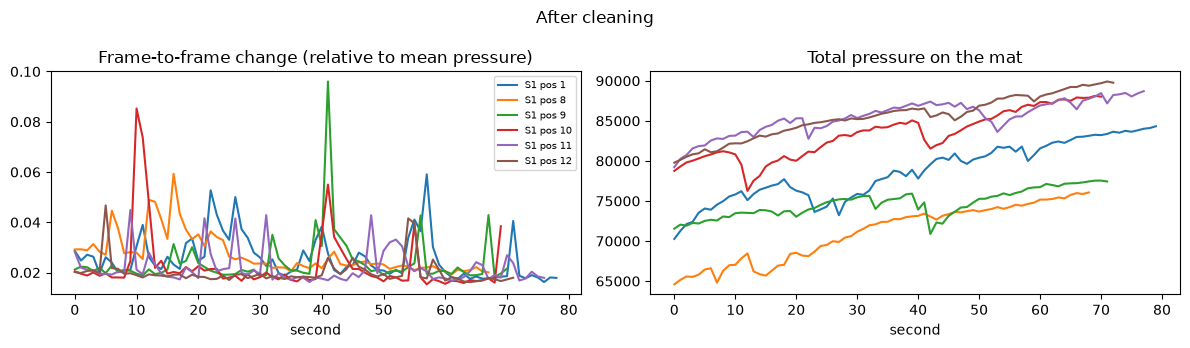

In [7]:
def drop_bad_frames(frames, factor=3.0):
    """Remove frames whose total pressure is far from the recording's median."""
    total = frames.sum(axis=(1, 2))
    med = np.median(total)
    keep = (total < factor * med) & (total > med / factor)
    return frames[keep], int((~keep).sum())

removed = []
for r in recordings:
    r["frames"], n_bad = drop_bad_frames(r["frames"])
    removed.append(n_bad)
removed = np.array(removed)
print(f"removed {removed.sum()} frames in total; per file: {dict(zip(*np.unique(removed, return_counts=True)))}")

plot_over_time(recordings[:6], "After cleaning")

After cleaning, the change from one second to the next is only about 2 % with a few small bumps (a breath, a small shift): people were asked to **lie still** for each recording.

Notice also the right plot: the total pressure **slowly rises by 10–15 %** over a minute and a half while the person lies still. That is sensor **creep**, which all soft pressure mats show, our Velostat mat included (the firmware's baseline/drift handling exists for the same reason). Per-window scaling in Part 2 removes most of it. That means the order of frames carries almost no information here, and a model that just averages the frames may do as well as a Transformer.

This is not a reason to stop. It is a reason to **always compare against a simple baseline**, and to expect the Transformer's real advantage later, on our own mat, where we will record real movements and turns. Today the goal is to build and understand the Transformer, and to measure honestly.

## Part 2 · From a hospital mat to our 10×10 mat

### Decision 4: how to shrink 64×32 to 10×10

| Option | What it does | Pros | Cons |
|---|---|---|---|
| **A. Whole mat → 10×10** (area average) | every 10×10 cell is the average of a block of sensors | simple, uses all the information | the whole bed squeezed into 10×10; our real mat is only 30×30 cm |
| **B. Crop a 30×30 cm patch → 10×10** | cut the area our mat would see, then average | matches our real mat | needs the exact sensor spacing (from the datasheet) and the patch position |

**We use A in this lesson** to learn the pipeline. Option B is the more honest match to our hardware; it is an experiment for Lesson 3, once we have the sensor spacing. Both use **area averaging**: every original sensor counts, nothing is thrown away (simple subsampling would skip rows and could miss a bony point).

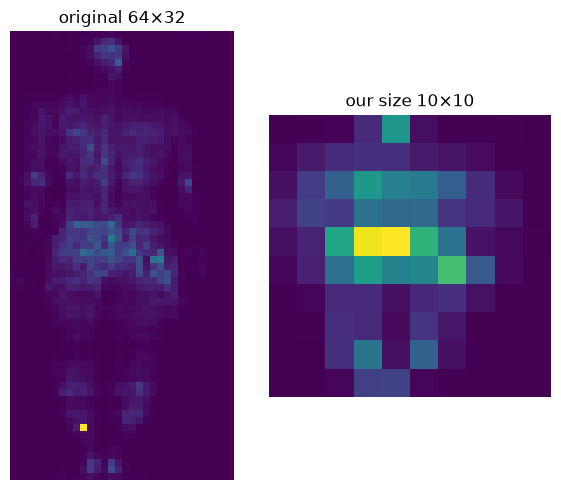

In [8]:
def area_resize(frames, h=10, w=10):
    """(T, H, W) -> (T, h, w) by averaging areas. Never drops rows or columns."""
    x = tf.convert_to_tensor(frames[..., None], dtype=tf.float32)
    return tf.image.resize(x, (h, w), method="area").numpy()[..., 0]

small = area_resize(recordings[0]["frames"])
fig, axes = plt.subplots(1, 2, figsize=(6, 5))
axes[0].imshow(recordings[0]["frames"][0]); axes[0].set_title("original 64×32")
axes[1].imshow(small[0]); axes[1].set_title("our size 10×10")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### Windows

The model reads **30 frames at a time** (30 seconds at 1 frame per second, the same rate the server will use). A recording of 90 frames gives several windows if we slide a 30-frame box along it:

```
frames:   0 ........................................ 89
window 1: [0 ......... 29]
window 2:           [10 ......... 39]          stride = 10 frames
window 3:                     [20 ......... 49]
...
```

Windows from the same recording **overlap** (window 1 and 2 share 20 frames). Keep that in mind for Part 3.

### Normalisation

Each window is divided by its own 99th percentile and clipped to 0–1. Why per window and not one global scale?

- PmatData, PoPu and our Velostat mat all measure in **different units** (raw counts, mmHg, voltage bytes). Per-window scaling removes the unit.
- We use the 99th percentile, not the maximum, so one noisy cell cannot squash everything else.
- The same function must run in training **and** on the server. Different scaling at serving time is a classic silent bug.

In [9]:
T, STRIDE = 30, 10

def normalise_window(x, eps=1e-6):
    """Scale a window to 0..1 by its own 99th percentile."""
    top = float(np.percentile(x, 99))
    return np.clip(x / max(top, eps), 0.0, 1.0).astype("float32")

X, y, groups, rec_ids = [], [], [], []
for i, r in enumerate(recordings):
    small = area_resize(r["frames"])
    for start in range(0, len(small) - T + 1, STRIDE):
        X.append(normalise_window(small[start:start + T]))
        y.append(CLASSES.index(r["label"]))
        groups.append(r["subject"])
        rec_ids.append(i)

X, y, groups, rec_ids = np.stack(X), np.array(y), np.array(groups), np.array(rec_ids)
print("X:", X.shape, " y:", y.shape)
print("windows per class:", dict(zip(CLASSES, np.bincount(y))))

X: (1409, 30, 10, 10)  y: (1409,)
windows per class: {'supine': np.int64(746), 'left': np.int64(336), 'right': np.int64(327)}


## Part 3 · How to split, and a baseline

### Decision 5: split by person

Imagine we split the windows **randomly**. Window 1 of `S3/2.txt` lands in training and window 2 (sharing 20 of its 30 frames) lands in testing. The test is then almost a copy of training data. Even worse, the model can learn to recognise *person 3's body shape* instead of the posture.

In the hospital, the model will always meet **a new person**. So the test must contain only people the model never saw. This is called a **group split** (the group is the person). Let's prove the difference with a quick scikit-learn baseline.

**The baseline:** average the 30 frames into one 10×10 picture (100 numbers), then logistic regression. No time, no attention. If the Transformer cannot beat this, attention is not helping.

**Metrics:** with unbalanced classes, plain accuracy lies (always saying "supine" already scores about 53 %). We report:
- **balanced accuracy**: the average of the accuracy on each class (chance = 33 %);
- **macro F1**: the F1 score of each class, averaged so every class counts the same.

In [10]:
X_flat = X.mean(axis=1).reshape(len(X), -1)  # (windows, 100): the time-averaged frame

def score(y_true, y_pred):
    return {"balanced_acc": round(balanced_accuracy_score(y_true, y_pred), 3),
            "macro_f1": round(f1_score(y_true, y_pred, average="macro"), 3)}

# Wrong way: random split of windows
Xa, Xb, ya, yb = train_test_split(X_flat, y, test_size=0.25, random_state=0, stratify=y)
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xa, ya)
print("random split (leaky):     ", score(yb, lr.predict(Xb)))

# Right way: test people are never in training
TEST_SUBJECTS = [11, 12, 13]
VAL_SUBJECTS = [9, 10]
is_test = np.isin(groups, TEST_SUBJECTS)
is_val = np.isin(groups, VAL_SUBJECTS)
is_train = ~is_test & ~is_val

lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_flat[is_train | is_val], y[is_train | is_val])
print("split by person (honest): ", score(y[is_test], lr.predict(X_flat[is_test])))

random split (leaky):      {'balanced_acc': 1.0, 'macro_f1': 1.0}
split by person (honest):  {'balanced_acc': 1.0, 'macro_f1': 1.0}


**Both are 100 %.** Surprise: with the *whole bed* visible, supine / left / right is so easy that even a linear model gets it perfectly, and leakage has nothing to inflate. Keep that in mind: the whole-bed view is much easier than what our 30 × 30 cm mat will see (Decision 4).

To *see* leakage, we need a harder task. Same data, same features, but now the label is the exact position number (17 classes: flat vs wedge vs foetal vs raised bed…). And a third test: can the model tell **who** is lying on the mat?

In [11]:
position = np.array([recordings[i]["position"] for i in rec_ids])   # 1..17 for each window

Xa, Xb, ya, yb = train_test_split(X_flat, position, test_size=0.25, random_state=0, stratify=position)
lr17 = LogisticRegression(max_iter=3000).fit(Xa, ya)
print("17 positions, random split (leaky):    ", score(yb, lr17.predict(Xb)))

lr17 = LogisticRegression(max_iter=3000).fit(X_flat[~is_test], position[~is_test])
print("17 positions, split by person (honest):", score(position[is_test], lr17.predict(X_flat[is_test])))

Xa, Xb, ga, gb = train_test_split(X_flat, groups, test_size=0.25, random_state=0, stratify=groups)
who = LogisticRegression(max_iter=3000).fit(Xa, ga)
print("which of the 13 people is it? (chance 0.077):", score(gb, who.predict(Xb)))

17 positions, random split (leaky):     {'balanced_acc': 0.965, 'macro_f1': 0.965}


17 positions, split by person (honest): {'balanced_acc': 0.777, 'macro_f1': 0.751}
which of the 13 people is it? (chance 0.077): {'balanced_acc': 0.818, 'macro_f1': 0.836}


Now the gap is clear: the random split scores about **0.97**, the honest split about **0.78**. And the last line shows *why*: from one averaged pressure picture the model recognises **which person** it is most of the time. With a random split, the model can partly answer "this is person 3, and person 3's left-wedge recording looked like this", which will never work on a new patient.

The honest number is always the one from a split by person. Any accuracy you ever put on the poster must come from one.

We now have three groups of people:

| Set | People | Purpose |
|---|---|---|
| train | S1–S8 | learn weights |
| validation | S9–S10 | early stopping |
| test | S11–S13 | the one honest number for this lesson |

In Part 6 we go further and rotate the test person through all 13 (leave-one-subject-out).

In [12]:
X_train, y_train = X[is_train], y[is_train]
X_val, y_val = X[is_val], y[is_val]
X_test, y_test = X[is_test], y[is_test]
print("train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)

# Unbalanced classes: give rarer classes more weight in the loss
cw = compute_class_weight("balanced", classes=np.arange(3), y=y_train)
CLASS_WEIGHT = dict(enumerate(cw))
print("class weights:", {CLASSES[k]: round(v, 2) for k, v in CLASS_WEIGHT.items()})

train (939, 30, 10, 10) | val (165, 30, 10, 10) | test (305, 30, 10, 10)
class weights: {'supine': np.float64(0.63), 'left': np.float64(1.42), 'right': np.float64(1.42)}


## Part 4 · The Transformer, piece by piece

### 4.1 The big idea: a sequence of tokens

A Transformer reads a **sequence of tokens** and lets every token look at every other token to decide what matters. In a language model a token is a word. For us:

```
window (30, 10, 10)  ->  flatten each frame  ->  30 tokens of 100 numbers
   frame 0  -> token 0  [100 numbers]
   frame 1  -> token 1  [100 numbers]
   ...
   frame 29 -> token 29 [100 numbers]
```

Compare with what you already know:

| Model | How it reads a sequence | Weak point |
|---|---|---|
| **Dense / MLP** | flattens everything into one vector | no idea of order or structure |
| **CNN (1D)** | looks at a few neighbours at a time | far-apart moments need many layers |
| **RNN / LSTM** | one step after another, carrying a memory | slow, forgets long ago, hard to train |
| **Transformer** | every token looks at **all** tokens in one step (attention) | needs more data; needs position info added |

### 4.2 Embedding: 100 numbers → 64 numbers

First, a `Dense(64)` layer projects every token from 100 to `d_model = 64` numbers. The same weights are used for all 30 tokens. This "embedding" lets the model build its own features (for example "pressure is on the left half") instead of using raw cells. Everything inside the Transformer then has width 64.

### 4.3 Self-attention by hand

This is the heart of the Transformer. For each token we compute three vectors with three learned matrices:

| Vector | Library analogy | Question it answers |
|---|---|---|
| **Query** `q` | what you type into the search box | "what am I looking for?" |
| **Key** `k` | the title on each book | "what do I contain?" |
| **Value** `v` | the content of the book | "what do I give if picked?" |

Then:

1. **Score** every pair: `score[i, j] = q_i · k_j` (dot product: big when they match).
2. **Scale**: divide by `√d_k` (we will see why in a second).
3. **Softmax** each row → attention weights; each row sums to 1.
4. **Mix**: output_i = Σ_j weight[i, j] · v_j.

In one line: **Attention(Q, K, V) = softmax(Q Kᵀ / √d_k) V**

Let's do it in NumPy with 4 tokens of width 8, so you can see every number.

In [13]:
rng = np.random.default_rng(0)
n_tokens, d_model, d_k = 4, 8, 8

x = rng.normal(size=(n_tokens, d_model))            # 4 tokens
W_q, W_k, W_v = (rng.normal(size=(d_model, d_k)) * 0.5 for _ in range(3))

Q, K, V = x @ W_q, x @ W_k, x @ W_v                 # each (4, 8)
scores = Q @ K.T / np.sqrt(d_k)                     # (4, 4): token i vs token j

def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)         # subtract max: same result, no overflow
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

weights = softmax(scores)                           # (4, 4), each row sums to 1
out = weights @ V                                   # (4, 8): one new vector per token

print("attention weights (row = who is looking, column = who is looked at):")
print(np.round(weights, 2))
print("row sums:", weights.sum(axis=1))
print("output shape:", out.shape, "= same shape as the input tokens")

attention weights (row = who is looking, column = who is looked at):
[[0.42 0.06 0.39 0.14]
 [0.95 0.   0.   0.04]
 [0.25 0.3  0.32 0.13]
 [0.18 0.3  0.17 0.34]]
row sums: [1. 1. 1. 1.]
output shape: (4, 8) = same shape as the input tokens


Each output token is a **weighted mix of all value vectors**. The weights are not fixed like in a CNN; they are computed from the data itself, so the model decides *for this window* which seconds matter.

**Why divide by √d_k?** Dot products of long vectors get big. Softmax of big numbers becomes almost one-hot (one weight ≈ 1, the rest ≈ 0), and then the gradients almost vanish and training stalls. Scaling keeps the scores in a comfortable range:

In [14]:
for d in [8, 64, 512]:
    q, k = rng.normal(size=(2, d)), rng.normal(size=(10, d))
    raw, scaled = softmax(q[0] @ k.T), softmax(q[0] @ k.T / np.sqrt(d))
    print(f"d={d:3d}  largest weight without scaling: {raw.max():.2f}   with scaling: {scaled.max():.2f}")

d=  8  largest weight without scaling: 0.53   with scaling: 0.27
d= 64  largest weight without scaling: 0.58   with scaling: 0.19
d=512  largest weight without scaling: 0.95   with scaling: 0.33


### 4.4 Multi-head attention

One attention computes one way of "looking". With **multi-head attention** we split the 64 numbers into **4 heads of 16**. Each head has its own Q, K, V, and can learn to look for something different (one head for the hip area, another for changes over time…). Then the 4 outputs are concatenated back to 64 and mixed by an output matrix `W_o`.

```
x (B, 30, 64)
  -> Q, K, V   = Dense(64) each              (B, 30, 64)
  -> split     -> 4 heads of 16              (B, 4, 30, 16)
  -> attention per head                      (B, 4, 30, 16) + weights (B, 4, 30, 30)
  -> merge heads                             (B, 30, 64)
  -> Dense(64) = W_o                         (B, 30, 64)
```

Here it is as a Keras layer, written from scratch with the same steps as the NumPy code. Read it slowly; every line maps to a line above.

In [15]:
@keras.saving.register_keras_serializable(package="perfusense")
class MultiHeadSelfAttention(layers.Layer):
    """Multi-head self-attention written from scratch."""

    def __init__(self, d_model, num_heads, dropout=0.0, **kwargs):
        super().__init__(**kwargs)
        assert d_model % num_heads == 0, "d_model must split evenly into heads"
        self.d_model, self.num_heads, self.dropout_rate = d_model, num_heads, dropout
        self.d_head = d_model // num_heads
        self.wq = layers.Dense(d_model, name="query")
        self.wk = layers.Dense(d_model, name="key")
        self.wv = layers.Dense(d_model, name="value")
        self.wo = layers.Dense(d_model, name="output")
        self.drop = layers.Dropout(dropout)

    def split_heads(self, x):
        # (B, T, d_model) -> (B, heads, T, d_head)
        b, t = tf.shape(x)[0], tf.shape(x)[1]
        x = tf.reshape(x, (b, t, self.num_heads, self.d_head))
        return tf.transpose(x, (0, 2, 1, 3))

    def call(self, x, training=False, return_attention=False):
        q = self.split_heads(self.wq(x))
        k = self.split_heads(self.wk(x))
        v = self.split_heads(self.wv(x))

        scores = tf.matmul(q, k, transpose_b=True) / tf.sqrt(float(self.d_head))  # (B, heads, T, T)
        weights = tf.nn.softmax(scores, axis=-1)
        out = tf.matmul(self.drop(weights, training=training), v)                 # (B, heads, T, d_head)

        b, t = tf.shape(x)[0], tf.shape(x)[1]
        out = tf.reshape(tf.transpose(out, (0, 2, 1, 3)), (b, t, self.d_model))   # merge heads
        out = self.wo(out)
        return (out, weights) if return_attention else out

    def get_config(self):
        return super().get_config() | {"d_model": self.d_model, "num_heads": self.num_heads,
                                       "dropout": self.dropout_rate}


mhsa = MultiHeadSelfAttention(d_model=64, num_heads=4)
dummy = tf.random.normal((2, 30, 64))           # batch of 2 windows, 30 tokens, width 64
out, w = mhsa(dummy, return_attention=True)
print("output:", out.shape, "| attention weights:", w.shape)

# Sanity check: Keras' built-in layer has exactly the same number of parameters
builtin = layers.MultiHeadAttention(num_heads=4, key_dim=16)
builtin(dummy, dummy)
print("our params:", mhsa.count_params(), "| keras.layers.MultiHeadAttention params:", builtin.count_params())

output: (2, 30, 64) | attention weights: (2, 4, 30, 30)
our params: 16640 | keras.layers.MultiHeadAttention params: 16640


Same parameter count: 4 matrices of 64×64 plus biases = 4 × 4,160 = 16,640. Our layer does the same maths as the built-in one; we wrote it ourselves so we can see (and later plot) the attention weights.

### 4.5 Why we need positions

Attention compares every token with every other token, but nothing in the formula says **which token came first**. Shuffle the 30 frames and each output is just shuffled the same way. After averaging over time, the result is *identical*. Let's prove it:

In [16]:
perm = np.random.default_rng(1).permutation(30)
a = mhsa(dummy)
b = mhsa(tf.gather(dummy, perm, axis=1))         # same frames, shuffled order

print("outputs follow the shuffle:      ", np.allclose(tf.gather(a, perm, axis=1), b, atol=1e-5))
print("time-averaged outputs identical: ", np.allclose(tf.reduce_mean(a, 1), tf.reduce_mean(b, 1), atol=1e-5))

outputs follow the shuffle:       True
time-averaged outputs identical:  True


So we **add a position vector** to each token before attention: token 0 gets vector p₀, token 1 gets p₁, and so on. Now "frame 3" and "frame 27" look different to the model even if the pressure is the same.

| Kind | How | When to use |
|---|---|---|
| **Learned** | a trainable (30, 64) table | fixed length (ours is always 30) |
| **Sinusoidal** (original 2017 paper) | fixed sine/cosine waves | sequences longer than any seen in training |

We use **learned** positions: our windows always have 30 frames.

In [17]:
@keras.saving.register_keras_serializable(package="perfusense")
class PositionEmbedding(layers.Layer):
    """Adds a learned vector to each time step: token t gets x_t + p_t."""

    def __init__(self, length, dim, **kwargs):
        super().__init__(**kwargs)
        self.length, self.dim = length, dim

    def build(self, input_shape):
        self.pos = self.add_weight(name="pos", shape=(self.length, self.dim),
                                   initializer="random_normal", trainable=True)

    def call(self, x):
        return x + self.pos   # (B, T, dim) + (T, dim): broadcast over the batch

    def get_config(self):
        return super().get_config() | {"length": self.length, "dim": self.dim}

### 4.6 The encoder block

Attention alone is not enough. A Transformer **encoder block** wraps it with three helpers:

```
x ──► LayerNorm ──► Multi-head self-attention ──► Dropout ──(+)──► x'
│                                                           ▲
└───────────────────────── residual ────────────────────────┘

x' ─► LayerNorm ──► Dense(128, GELU) ──► Dropout ──► Dense(64) ──(+)──► output
│                                                                ▲
└──────────────────────────── residual ──────────────────────────┘
```

| Piece | What it does | Why |
|---|---|---|
| **Residual** `x + f(x)` | adds the input back to the output | the block only has to learn a *correction*; gradients flow straight through, so deep stacks train well |
| **LayerNorm** | rescales each token's 64 numbers to mean 0, std 1 | keeps values stable. Unlike **BatchNorm** (which you may know from CNNs), it does not depend on the other samples in the batch, so it behaves the same in training and serving |
| **Feed-forward** 64→128→64 | a small MLP applied to each token on its own | attention *mixes* tokens; the feed-forward *thinks* about each token |
| **GELU** | a smooth version of ReLU | the standard choice in Transformers; small negative values are not cut to exactly 0 |
| **Dropout** | randomly zeroes some values in training | less overfitting; we have few people |

We put LayerNorm *before* attention and feed-forward ("pre-norm"). The 2017 paper put it after; pre-norm trains more reliably, so most modern models use it.

In [18]:
@keras.saving.register_keras_serializable(package="perfusense")
class EncoderBlock(layers.Layer):
    """Pre-norm Transformer encoder block: attention + feed-forward, each with a residual."""

    def __init__(self, d_model=64, num_heads=4, ff_dim=128, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.d_model, self.num_heads, self.ff_dim, self.dropout_rate = d_model, num_heads, ff_dim, dropout
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.attn = MultiHeadSelfAttention(d_model, num_heads, dropout)
        self.drop1 = layers.Dropout(dropout)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.ff1 = layers.Dense(ff_dim, activation="gelu")
        self.drop2 = layers.Dropout(dropout)
        self.ff2 = layers.Dense(d_model)

    def call(self, x, training=False, return_attention=False):
        a, weights = self.attn(self.norm1(x), training=training, return_attention=True)
        x = x + self.drop1(a, training=training)                          # residual 1
        f = self.ff2(self.drop2(self.ff1(self.norm2(x)), training=training))
        x = x + f                                                          # residual 2
        return (x, weights) if return_attention else x

    def get_config(self):
        return super().get_config() | {"d_model": self.d_model, "num_heads": self.num_heads,
                                       "ff_dim": self.ff_dim, "dropout": self.dropout_rate}

### 4.7 The full model

```
input (30, 10, 10)
  -> Reshape          (30, 100)   each frame becomes one token
  -> Dense(64)        (30, 64)    embedding
  -> + positions      (30, 64)
  -> EncoderBlock ×2  (30, 64)
  -> LayerNorm
  -> average over time (64)       one summary vector for the whole window
  -> Dropout + Dense(3)  (3)      logits: one score per class
```

**Encoder vs decoder.** You may have heard of GPT (decoder) and BERT (encoder). A **decoder** generates a sequence one token at a time and uses a *causal mask* so a token cannot look at the future. An **encoder** reads the whole sequence at once and summarises it. We classify a finished 30-second window, so we only need the **encoder**; no mask.

**Average vs a [CLS] token.** BERT adds a special extra token and reads the class from it. Averaging all 30 outputs is simpler and works just as well for short windows.

In [19]:
def build_transformer(t=30, h=10, w=10, num_classes=3, d_model=64, heads=4, ff=128, blocks=2, dropout=0.1):
    inp = keras.Input(shape=(t, h, w), name="window")
    x = layers.Reshape((t, h * w), name="frames_to_tokens")(inp)
    x = layers.Dense(d_model, name="embedding")(x)
    x = PositionEmbedding(t, d_model, name="positions")(x)
    for i in range(blocks):
        x = EncoderBlock(d_model, heads, ff, dropout, name=f"encoder_{i}")(x)
    x = layers.LayerNormalization(epsilon=1e-6, name="final_norm")(x)
    x = layers.GlobalAveragePooling1D(name="average_over_time")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(num_classes, name="logits")(x)   # no softmax: the loss does it
    return keras.Model(inp, out, name="posture_transformer")


def build_baseline(t=30, h=10, w=10, num_classes=3):
    """No attention, no time: average the frames, then a small MLP."""
    inp = keras.Input(shape=(t, h, w), name="window")
    x = layers.GlobalAveragePooling1D(name="average_over_time")(layers.Reshape((t, h * w))(inp))
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(num_classes, name="logits")(x)
    return keras.Model(inp, out, name="baseline_mlp")


model = build_transformer()
model.summary()

Model: "posture_transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ window (InputLayer)             │ (None, 30, 10, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ frames_to_tokens (Reshape)      │ (None, 30, 100)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Dense)               │ (None, 30, 64)         │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positions (PositionEmbedding)   │ (None, 30, 64)         │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_0 (EncoderBlock)        │ (None, 30, 64)         │        33,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_1 (EncoderBlock)        │ (None, 30, 64)         │        33,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ final_norm (LayerNormalization) │ (None, 30, 64)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_over_time               │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)

About **76,000 parameters**. Where they come from:

| Part | Calculation | Parameters |
|---|---|---|
| embedding | 100 × 64 + 64 | 6,464 |
| positions | 30 × 64 | 1,920 |
| one encoder block | LayerNorm 128 + attention 16,640 + LayerNorm 128 + Dense 64→128 8,320 + Dense 128→64 8,256 | 33,472 |
| two blocks | 2 × 33,472 | 66,944 |
| final LayerNorm + logits | 128 + (64 × 3 + 3) | 323 |
| **total** | | **75,651** |

Small enough to train on a laptop CPU in a few minutes. Far too big for the ESP32, so it will run on the server.

## Part 5 · Train it

| Choice | Value | Why |
|---|---|---|
| Loss | `SparseCategoricalCrossentropy(from_logits=True)` | labels are integers 0/1/2; the model outputs logits, and the loss applies softmax itself in a numerically safer way |
| Optimizer | Adam, learning rate 0.001 | a reliable default |
| Class weights | from Part 3 | left and right count as much as supine |
| Early stopping | watch validation loss, patience 8, keep the best weights | stop before overfitting the training people |
| Batch size | 32 | |

In [20]:
def train(model, X_tr, y_tr, X_va, y_va, epochs=60, verbose=0):
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    cw = dict(enumerate(compute_class_weight("balanced", classes=np.arange(3), y=y_tr)))
    return model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=epochs, batch_size=32,
                     class_weight=cw, callbacks=[stop], verbose=verbose)

keras.utils.set_random_seed(42)
transformer = build_transformer()
t0 = time.time()
hist = train(transformer, X_train, y_train, X_val, y_val, verbose=2)
print(f"trained in {time.time() - t0:.0f} s, best epoch {np.argmin(hist.history['val_loss']) + 1}")

Epoch 1/60


30/30 - 8s - 252ms/step - accuracy: 0.8818 - loss: 0.3158 - val_accuracy: 0.9152 - val_loss: 0.4067


Epoch 2/60


30/30 - 1s - 28ms/step - accuracy: 0.9957 - loss: 0.0218 - val_accuracy: 0.9152 - val_loss: 0.3590


Epoch 3/60


30/30 - 1s - 28ms/step - accuracy: 1.0000 - loss: 0.0026 - val_accuracy: 0.9273 - val_loss: 0.2878


... (23 outputs left out)

30/30 - 1s - 28ms/step - accuracy: 1.0000 - loss: 2.0658e-04 - val_accuracy: 0.9152 - val_loss: 0.2685


Epoch 16/60


30/30 - 1s - 26ms/step - accuracy: 1.0000 - loss: 1.9670e-04 - val_accuracy: 0.9152 - val_loss: 0.2685


trained in 20 s, best epoch 8


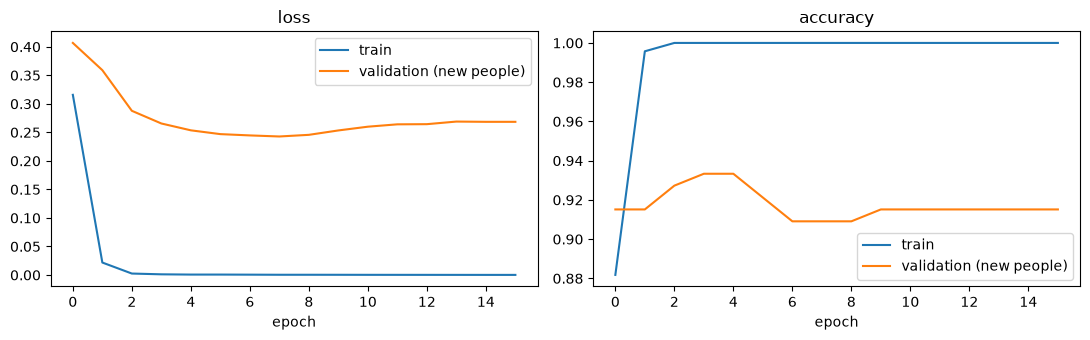

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for key, ax in zip(["loss", "accuracy"], axes):
    ax.plot(hist.history[key], label="train")
    ax.plot(hist.history[f"val_{key}"], label="validation (new people)")
    ax.set_title(key); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

**How to read the curves (another pair of words people mix up):**

- **Underfitting**: both curves are bad. The model is too small or trained too short.
- **Overfitting**: training keeps improving while validation stops or gets worse. The model is memorising the training people. Early stopping keeps the weights from the best validation epoch.

Now the test people (S11–S13), which the model has never seen, against the baseline trained the same way:

Transformer: {'balanced_acc': 0.956, 'macro_f1': 0.953}
Baseline:    {'balanced_acc': 1.0, 'macro_f1': 1.0}


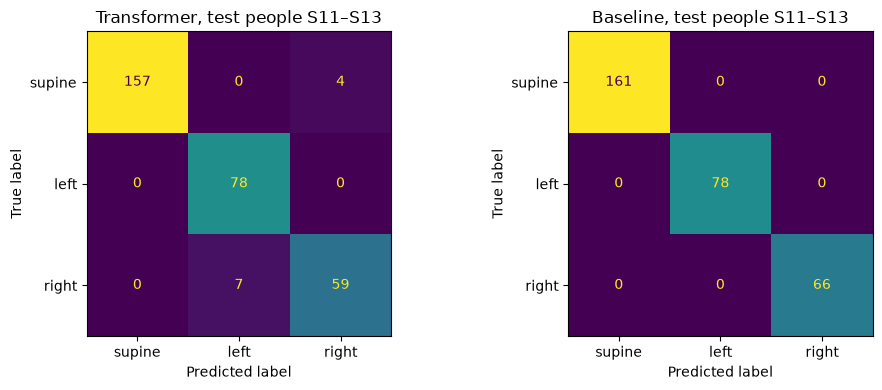

In [22]:
keras.utils.set_random_seed(42)
baseline = build_baseline()
train(baseline, X_train, y_train, X_val, y_val)

pred_tf = transformer.predict(X_test, verbose=0).argmax(axis=1)
pred_bl = baseline.predict(X_test, verbose=0).argmax(axis=1)
print("Transformer:", score(y_test, pred_tf))
print("Baseline:   ", score(y_test, pred_bl))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, name in [(axes[0], pred_tf, "Transformer"), (axes[1], pred_bl, "Baseline")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1, 2]),
                           display_labels=CLASSES).plot(ax=ax, colorbar=False)
    ax.set_title(f"{name}, test people S11–S13")
plt.tight_layout(); plt.show()

**Reading a confusion matrix:** rows are the truth, columns are the prediction. The diagonal is correct. Off-diagonal cells show *which* mistakes happen. For PerfuSense, mixing up **left and right** is the worst mistake: the dashboard would say a side is unloaded when it is not.

In my run the Transformer made a few of exactly that mistake (some "right" windows called "left") while the simple baseline was perfect on these three people. Your numbers may differ slightly. One split with three people is noisy, so don't conclude anything yet: Part 6 gives the fair comparison.

### Look inside: what does the model attend to?

Our own attention layer can return its weights. Let's run one test window through the first encoder block and draw the 30×30 attention map of each head.

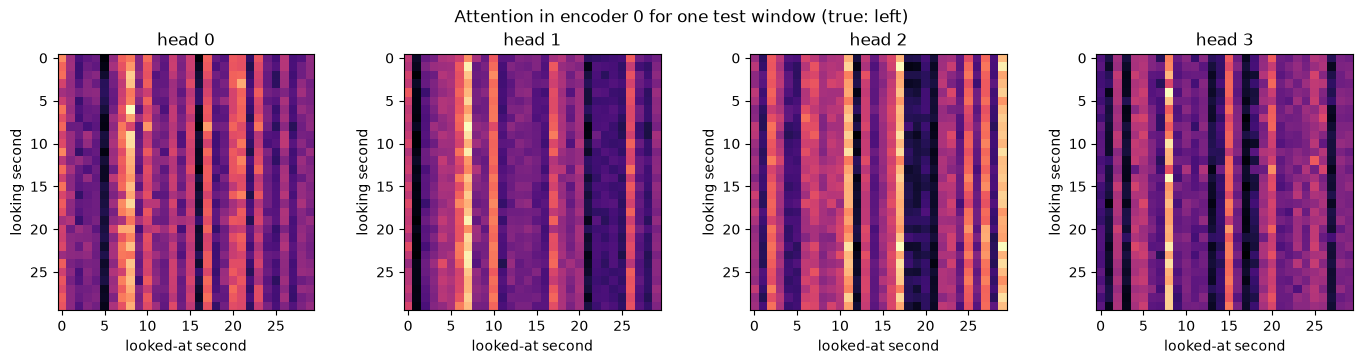

In [23]:
def attention_maps(model, window, block=0):
    """Run one window through the model up to encoder `block`; return its weights (heads, 30, 30)."""
    x = window[None]
    x = model.get_layer("frames_to_tokens")(x)
    x = model.get_layer("embedding")(x)
    x = model.get_layer("positions")(x)
    for i in range(block):
        x = model.get_layer(f"encoder_{i}")(x)
    _, w = model.get_layer(f"encoder_{block}")(x, return_attention=True)
    return w[0].numpy()

i = int(np.flatnonzero(y_test == CLASSES.index("left"))[0])
maps = attention_maps(transformer, X_test[i])
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for h, ax in enumerate(axes):
    ax.imshow(maps[h], cmap="magma"); ax.set_title(f"head {h}")
    ax.set_xlabel("looked-at second"); ax.set_ylabel("looking second")
plt.suptitle(f"Attention in encoder 0 for one test window (true: {CLASSES[y_test[i]]})")
plt.tight_layout(); plt.show()

Each row shows where one second "looks". If the rows are almost flat, the model spreads its attention evenly over the window, which is what we expect when the person lies still: every second carries the same information. Vertical stripes mean some seconds are seen as more useful by everyone (for example a moment of movement). Attention maps are a hint, not proof of what the model "thinks".

## Part 6 · The honest number: leave one person out

Three test people is a small test: one unusual person changes the result a lot. **Leave-one-subject-out** (LOSO) cross-validation trains 13 times; each time a different person is the test, one other person is the validation set, and the remaining 11 are training. We report the mean and the spread over the 13 people.

This trains 26 models (Transformer + baseline per person), so it takes about 10–15 minutes on a laptop CPU. Set `RUN_LOSO = False` to skip it while you experiment.

In [24]:
RUN_LOSO = True

rows = []
if RUN_LOSO:
    subjects = sorted(set(groups))
    t0 = time.time()
    for k, test_s in enumerate(subjects):
        val_s = subjects[(k + 1) % len(subjects)]          # the next person is validation
        te, va = groups == test_s, groups == val_s
        tr = ~te & ~va
        for name, builder in [("transformer", build_transformer), ("baseline", build_baseline)]:
            keras.backend.clear_session()   # forget old models: keeps memory and speed steady
            keras.utils.set_random_seed(42)
            m = builder()
            train(m, X[tr], y[tr], X[va], y[va])
            pred = m.predict(X[te], verbose=0).argmax(axis=1)
            rows.append({"test_subject": test_s, "model": name} | score(y[te], pred))
        print(f"S{test_s:<2} done ({time.time() - t0:.0f} s)")

    loso = pd.DataFrame(rows)
    table = loso.pivot(index="test_subject", columns="model", values="balanced_acc")
    print(table)
    print("\nmean ± std over people:")
    print(loso.groupby("model")[["balanced_acc", "macro_f1"]].agg(["mean", "std"]).round(3))

S1  done (35 s)


S2  done (115 s)


S3  done (173 s)


S4  done (203 s)


S5  done (233 s)


S6  done (259 s)


... (3 outputs left out)

S10 done (416 s)


S11 done (448 s)


S12 done (529 s)


S13 done (559 s)
model         baseline  transformer
test_subject                       
1                1.000        0.965
2                0.930        1.000
3                1.000        1.000
4                0.895        1.000
5                1.000        1.000
6                1.000        1.000
7                0.962        1.000
8                1.000        0.915
9                0.983        0.957
10               0.887        0.850
11               1.000        1.000
12               1.000        0.979
13               0.917        0.833

mean ± std over people:
            balanced_acc        macro_f1       
                    mean    std     mean    std
model                                          
baseline           0.967  0.044    0.968  0.042
transformer        0.961  0.059    0.965  0.054


## What we learned

My run of the leave-one-subject-out test (balanced accuracy over 13 people):

| Model | Mean | Std | Worst person |
|---|---|---|---|
| Baseline (average frames + MLP, ~6,700 params) | 0.967 | 0.044 | 0.887 |
| Transformer (~75,700 params) | 0.961 | 0.059 | 0.833 |

- **The two are tied.** The difference (0.006) is far smaller than the spread between people (≈ 0.05). The Transformer is 11× bigger and not better. This is the result we predicted in Part 1: people lie still, so the order of frames carries almost no information, and attention over time has nothing extra to use. That is a valid scientific result, not a failure, and it tells us what data we need: recordings with **real movement and turns**, from our own mat.
- **Some people are harder than others** (S10 and S13 are the lowest for both models). With only 13 people, always report the spread, not just the mean.
- **The whole-bed view is too easy.** ~97 % with a linear model means this setup does not test the real problem. The real test is the 30 × 30 cm patch (Lesson 3).
- **Look before you train.** The first frames of every file were broken, values go above the documented 0–1000, and three of the five downloads hold no data yet. Plots found all of it.
- **Split by person.** On the harder 17-position task, a random split scored ≈ 0.97 and the honest split ≈ 0.78.
- **You built every part of a Transformer:** tokens, embedding, learned positions, scaled dot-product attention, multi-head attention, residuals, LayerNorm, feed-forward, pooling, logits.

## Your turn

1. **Remove the positions.** In `build_transformer`, comment out the `PositionEmbedding` line and run Part 5 again. Does the score change? Given Part 4.5, what would you expect on still data?
2. **One head vs four.** Build with `heads=1` (then `d_head = 64`). Compare scores and parameter counts.
3. **Shorter windows.** Set `T = 10` in Part 2 and re-run. More windows, less time per window: better or worse?
4. **Mirror augmentation.** Flip a window left↔right with `X[..., ::-1]`. What must happen to the label? (Hint: supine stays supine; left becomes right.) Add the mirrored training windows and re-train.

## Next lessons

| Lesson | Topic |
|---|---|
| 2 | PoPu-Data: a second real dataset, the **empty bed** class, combining two datasets with different sensors |
| 3 | Crop a 30 × 30 cm patch (what our mat really sees) instead of the whole bed |
| 4 | Pre-train on synthetic data (PressurePose / BodyPressureSD), fine-tune on real data |
| 5 | Save the model and serve it with FastAPI for the PerfuSense server |

**Licence / citation:** PmatData is ODC-By 1.0. Cite: M. B. Pouyan et al., "A pressure map dataset for posture and subject analytics," IEEE BHI 2017, and PhysioNet (Goldberger et al.).